# Módulo 1 — Preprocesamiento de Texto para Mantenimiento Industrial
**Pungo Academy · NLP para Mantenimiento Industrial (Nivel Avanzado)**

## Objetivo
Construir un pipeline reproducible para limpiar, normalizar, expandir jerga de campo y explorar texto no estructurado de órdenes de trabajo (MWOs) en una facilidad de producción de petróleo, culminando en vectorización **TF-IDF** y análisis Pareto de impacto económico por modo de falla.

## Contenido
1. Carga y auditoría de 3,030 órdenes de trabajo industriales
2. Normalización básica preservando tags de equipo (`P-101A`, `FT-1503`) y unidades (`4.5mm`, `93°C`)
3. Expansión de abreviaturas (`mto`, `bba`, `rdto`, `cui`, `loto`) y corrección ortográfica de campo
4. Tokenización con stopwords en español adaptadas a mantenimiento
5. Análisis exploratorio textual (EDA) y Pareto de costo por modo de falla
6. Vectorización TF-IDF con unigramas y bigramas discriminantes

In [1]:
import re
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer

# Paleta corporativa oficial Pungo Tech 2027
PUNGO_NAVY = "#0D202B"
PUNGO_BLUE = "#007297"
PUNGO_LIME = "#8EC14B"
PUNGO_AMBER = "#E8820C"
PUNGO_RED = "#C0392B"
PUNGO_SLATE = "#475569"
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["figure.dpi"] = 150
plt.rcParams["font.size"] = 11
plt.rcParams["axes.edgecolor"] = "#CBD5E1"
plt.rcParams["axes.titleweight"] = "bold"
plt.style.use("seaborn-v0_8-whitegrid")
print("Entorno Notebook 01 listo.")

Entorno Notebook 01 listo.


## 1. Carga y Exploración del Dataset de Órdenes de Trabajo
Trabajaremos con el repositorio oficial de **3,030 órdenes de trabajo** de una facilidad petrolera, alojado en CloudFront para ejecución directa en Google Colab.

In [2]:
DATA_URL = "https://d29ikw7e1z6k4e.cloudfront.net/curso_nlp/curso_nlp_work_orders.csv"
df = pd.read_csv(DATA_URL, parse_dates=["fecha_creacion", "fecha_cierre"])

print(f"Dataset shape: {df.shape}")
print(f"Columnas ({len(df.columns)}): {df.columns.tolist()}")
df[["wo_id", "fecha_creacion", "equipo_tag", "sistema", "tipo_orden", "modo_falla", "costo_estimado_usd"]].head(4)

Dataset shape: (3030, 17)
Columnas (17): ['wo_id', 'fecha_creacion', 'fecha_cierre', 'equipo_tag', 'equipo_nombre', 'sistema', 'ubicacion', 'tipo_orden', 'prioridad', 'descripcion_problema', 'descripcion_trabajo', 'modo_falla', 'causa_raiz', 'especialidad', 'horas_hombre', 'estado', 'costo_estimado_usd']


,wo_id,fecha_creacion,equipo_tag,sistema,tipo_orden,modo_falla,costo_estimado_usd
0,OT-2024-02083,2023-01-01,V-102,separacion,correctivo,falla_instrumentacion,23530.0
1,OT-2024-00160,2023-01-01,P-101B,bombeo,preventivo,falla_instrumentacion,14019.0
2,OT-2024-00955,2023-01-01,M-201,inyeccion_agua,correctivo,desgaste_mecanico,2463.0
3,OT-2024-02531,2023-01-02,E-102,compresion,predictivo,falla_instrumentacion,7228.0


In [3]:
print("=" * 64)
print("RESUMEN EJECUTIVO DEL DATASET DE ÓRDENES DE TRABAJO")
print("=" * 64)
print(f"Total de órdenes de trabajo : {len(df):,}")
print(f"Rango temporal              : {df['fecha_creacion'].min().date()} → {df['fecha_creacion'].max().date()}")
print(f"Equipos únicos (tags)       : {df['equipo_tag'].nunique()} equipos en {df['sistema'].nunique()} sistemas")
print(f"Costo total estimado        : ${df['costo_estimado_usd'].sum():,.0f} USD")

nulls = df.isnull().sum()
print("\nColumnas con valores nulos:")
print(nulls[nulls > 0].to_string())

print("\nDistribución por tipo de orden:")
print(df["tipo_orden"].value_counts().to_string())
print("\nDistribución por modo de falla:")
print(df["modo_falla"].value_counts().to_string())

RESUMEN EJECUTIVO DEL DATASET DE ÓRDENES DE TRABAJO
Total de órdenes de trabajo : 3,030
Rango temporal              : 2023-01-01 → 2024-12-30
Equipos únicos (tags)       : 37 equipos en 12 sistemas
Costo total estimado        : $35,343,244 USD

Columnas con valores nulos:
fecha_cierre           1296
descripcion_trabajo     232
causa_raiz              353
horas_hombre            159
costo_estimado_usd      272

Distribución por tipo de orden:
tipo_orden
correctivo    1637
preventivo     927
predictivo     466

Distribución por modo de falla:
modo_falla
desgaste_mecanico        545
fuga                     492
corrosion                432
falla_instrumentacion    363
falla_electrica          315
obstruccion              308
sobrecalentamiento       295
vibracion_excesiva       280


In [4]:
print("EJEMPLOS REALES DE DESCRIPCIONES DE PROBLEMAS")
print("=" * 64)
for _, row in df.sample(5, random_state=42).iterrows():
    print(f"\n[{row['modo_falla']} | {row['equipo_tag']} | ${row['costo_estimado_usd']:,.0f}]")
    print(f"  Problema : {row['descripcion_problema']}")
    print(f"  Trabajo  : {row['descripcion_trabajo']}")

EJEMPLOS REALES DE DESCRIPCIONES DE PROBLEMAS

[corrosion | TK-101 | $14,605]
  Problema : Se programa reparación de TK101 por corrosión por picadura en boquilla de salida. Última inspección hace 3 meses mostraba condición aceptable.
  Trabajo  : Se instaló camisa de reparación tipo B en válvula de venteo. Se realizó inspección radiográfica post-soldadura: sin defectos.

[sobrecalentamiento | LN-GAS-001 | $3,927]
  Problema : Motor del LN-GAS-001 operando a 111°C. Temperatura ambiente: 27°C. Ventilador funcionando correctamente.
  Trabajo  : Se limpió enfriador E-201 del LN-GAS-001. Temperatura de aceite normalizada a 121°C.

[falla_electrica | M-101A | $16,276]
  Problema : vibración alta
  Trabajo  : Se cambió contactor principal del M-101A (Motor eléctrico bomba P-101A). Se verificó circuito de control. Arranca y opera normal.

[falla_instrumentacion | TK-102 | $3,554]
  Problema : TK102 sin señal en DCS. Se verifica cableado: cable cortado en bornera.
  Trabajo  : Se cambió posicio

## 2. Limpieza de Texto Preservando Identificadores Industriales
En PLN general solemos eliminar toda puntuación y números. **En mantenimiento industrial eso destruye información crítica**: perderíamos los tags (`P-101A`, `XV-1001`) y las mediciones (`93°C`, `4.5 mm/s`). Nuestra función `limpiar_texto_basico` conserva letras, dígitos, puntos decimales, guiones, barras, `%` y `°`.

In [5]:
def limpiar_texto_basico(texto: str) -> str:
    """Normaliza minúsculas y acentos manteniendo tags de equipo y magnitudes."""
    if pd.isna(texto):
        return ""
    texto = str(texto).lower()
    for orig, rep in [("á", "a"), ("é", "e"), ("í", "i"), ("ó", "o"), ("ú", "u"), ("ñ", "n")]:
        texto = texto.replace(orig, rep)
    texto = re.sub(r"[^a-z0-9\s\.\-\/\%°]", " ", texto)
    texto = re.sub(r"\s+", " ", texto).strip()
    return texto

ejemplo = df["descripcion_problema"].iloc[125]
print(f"ORIGINAL : {ejemplo}")
print(f"LIMPIO   : {limpiar_texto_basico(ejemplo)}")

ORIGINAL : Termografía detecta punto caliente en fuente de alimentación del FT-1503: 93°C. Riesgo de falla.
LIMPIO   : termografia detecta punto caliente en fuente de alimentacion del ft-1503 93°c. riesgo de falla.


## 3. Expansión de Abreviaturas y Corrección de Jerga de Campo
Los técnicos escriben bajo presión en turno nocturno usando abreviaturas (`mto`, `bba`, `rdto`, `vdf`, `cui`) y errores tipográficos frecuentes (`vonba`, `balvula`, `rodaminto`). Construimos diccionarios curados de dominio.

In [6]:
ABREVIACIONES = {
    "mto": "mantenimiento",
    "mto.": "mantenimiento",
    "mtto": "mantenimiento",
    "prev": "preventivo",
    "prev.": "preventivo",
    "temp": "temperatura",
    "temp.": "temperatura",
    "ta": "temperatura",
    "pres": "presion",
    "pres.": "presion",
    "vibr": "vibracion",
    "vibr.": "vibracion",
    "insp": "inspeccion",
    "insp.": "inspeccion",
    "oper": "operacion",
    "oper.": "operacion",
    "bba": "bomba",
    "comp.": "compresor",
    "interc.": "intercambiador",
    "rdto": "rodamiento",
    "ut": "ultrasonido",
    "ndt": "ensayo no destructivo",
    "ot": "orden de trabajo",
    "hh": "horas hombre",
    "dp": "diferencial de presion",
    "dt": "diferencial de temperatura",
    "vdf": "variador de frecuencia",
    "dcs": "sistema de control distribuido",
    "plc": "controlador logico programable",
    "rpm": "revoluciones por minuto",
    "psi": "libras por pulgada cuadrada",
    "loto": "bloqueo y etiquetado",
    "bsw": "agua y sedimento basico",
    "cui": "corrosion bajo aislamiento",
}

def expandir_abreviaciones(texto: str, diccionario: dict = ABREVIACIONES) -> str:
    """Expande abreviaturas industriales palabra por palabra."""
    return " ".join(diccionario.get(p, p) for p in texto.split())

texto_test = "se programo mto prev de bba p-101. verificar vibr y temp por cui"
print(f"ORIGINAL  : {texto_test}")
print(f"EXPANDIDO : {expandir_abreviaciones(texto_test)}")

ORIGINAL  : se programo mto prev de bba p-101. verificar vibr y temp por cui
EXPANDIDO : se programo mantenimiento preventivo de bomba p-101. verificar vibracion y temperatura por corrosion bajo aislamiento


In [7]:
CORRECCIONES = {
    "vonba": "bomba",
    "balvula": "valvula",
    "rodaminto": "rodamiento",
    "compressor": "compresor",
    "tempertura": "temperatura",
    "emrgencia": "emergencia",
    "vlvula": "valvula",
}

def corregir_errores(texto: str, correcciones: dict = CORRECCIONES) -> str:
    """Corrige typos frecuentes registrados en el CMMS."""
    for error, correcto in correcciones.items():
        texto = texto.replace(error, correcto)
    return texto

def preprocesar_texto(texto: str) -> str:
    """Pipeline secuencial: limpieza básica -> expansión -> corrección ortográfica."""
    texto = limpiar_texto_basico(texto)
    texto = expandir_abreviaciones(texto)
    texto = corregir_errores(texto)
    return texto

df["descripcion_limpia"] = df["descripcion_problema"].apply(preprocesar_texto)

print("COMPARATIVA ANTES vs DESPUÉS DEL PIPELINE")
print("=" * 64)
for i in range(3):
    print(f"\n[{df['wo_id'].iloc[i]}]")
    print(f"  ORIGINAL : {df['descripcion_problema'].iloc[i]}")
    print(f"  LIMPIO   : {df['descripcion_limpia'].iloc[i]}")

COMPARATIVA ANTES vs DESPUÉS DEL PIPELINE

[OT-2024-02083]
  ORIGINAL : Válvula de control V-102 no responde a señal del controlador. Posicionador descalibrado.
  LIMPIO   : valvula de control v-102 no responde a senal del controlador. posicionador descalibrado.

[OT-2024-00160]
  ORIGINAL : Lectura errática de Bomba centrífuga de transferencia de crudo (respaldo). Oscila entre 23.9 y 88.5 °C. Se sospecha ruido eléctrico.
  LIMPIO   : lectura erratica de bomba centrifuga de transferencia de crudo respaldo . oscila entre 23.9 y 88.5 °c. se sospecha ruido electrico.

[OT-2024-00955]
  ORIGINAL : Compresor M-201 con caída de eficiencia. Flujo actual 49% del nominal. Posible erosión en etapas.
  LIMPIO   : compresor m-201 con caida de eficiencia. flujo actual 49% del nominal. posible erosion en etapas.


## 4. Tokenización y Filtrado de Stopwords en Español
Removemos palabras funcionales de alto volumen (`de`, `la`, `en`, `por`) para aislar términos técnicos portadores de señal.

In [8]:
STOP_WORDS_ES = {
    "de", "la", "el", "en", "y", "a", "los", "del", "las", "un", "por",
    "con", "una", "su", "para", "es", "al", "lo", "como", "se", "que",
    "no", "mas", "o", "le", "ha", "este", "si", "ya", "e", "entre",
    "muy", "sin", "sobre", "ser", "tiene", "tambien", "fue", "son",
}

def tokenizar(texto: str, stop_words: set = STOP_WORDS_ES) -> list[str]:
    """Divide texto preprocesado en tokens filtrando stopwords y monoletras."""
    return [t for t in texto.split() if t not in stop_words and len(t) > 1]

df["tokens"] = df["descripcion_limpia"].apply(tokenizar)
print("Ejemplo de tokenización:")
print(f"  Texto  : {df['descripcion_limpia'].iloc[0]}")
print(f"  Tokens : {df['tokens'].iloc[0]}")
print("\nEstadísticas de tokens por orden de trabajo:")
print(df["tokens"].apply(len).describe().round(2).to_string())

Ejemplo de tokenización:
  Texto  : valvula de control v-102 no responde a senal del controlador. posicionador descalibrado.
  Tokens : ['valvula', 'control', 'v-102', 'responde', 'senal', 'controlador.', 'posicionador', 'descalibrado.']

Estadísticas de tokens por orden de trabajo:
count    3030.00
mean       12.19
std         3.58
min         1.00
25%        11.00
50%        12.00
75%        14.00
max        23.00


## 5. Análisis Exploratorio Textual (EDA) y Pareto Económico
Antes de entrenar modelos, cuantificamos tanto la morfología del texto (longitud, vocabulario) como el **impacto económico por modo de falla**.

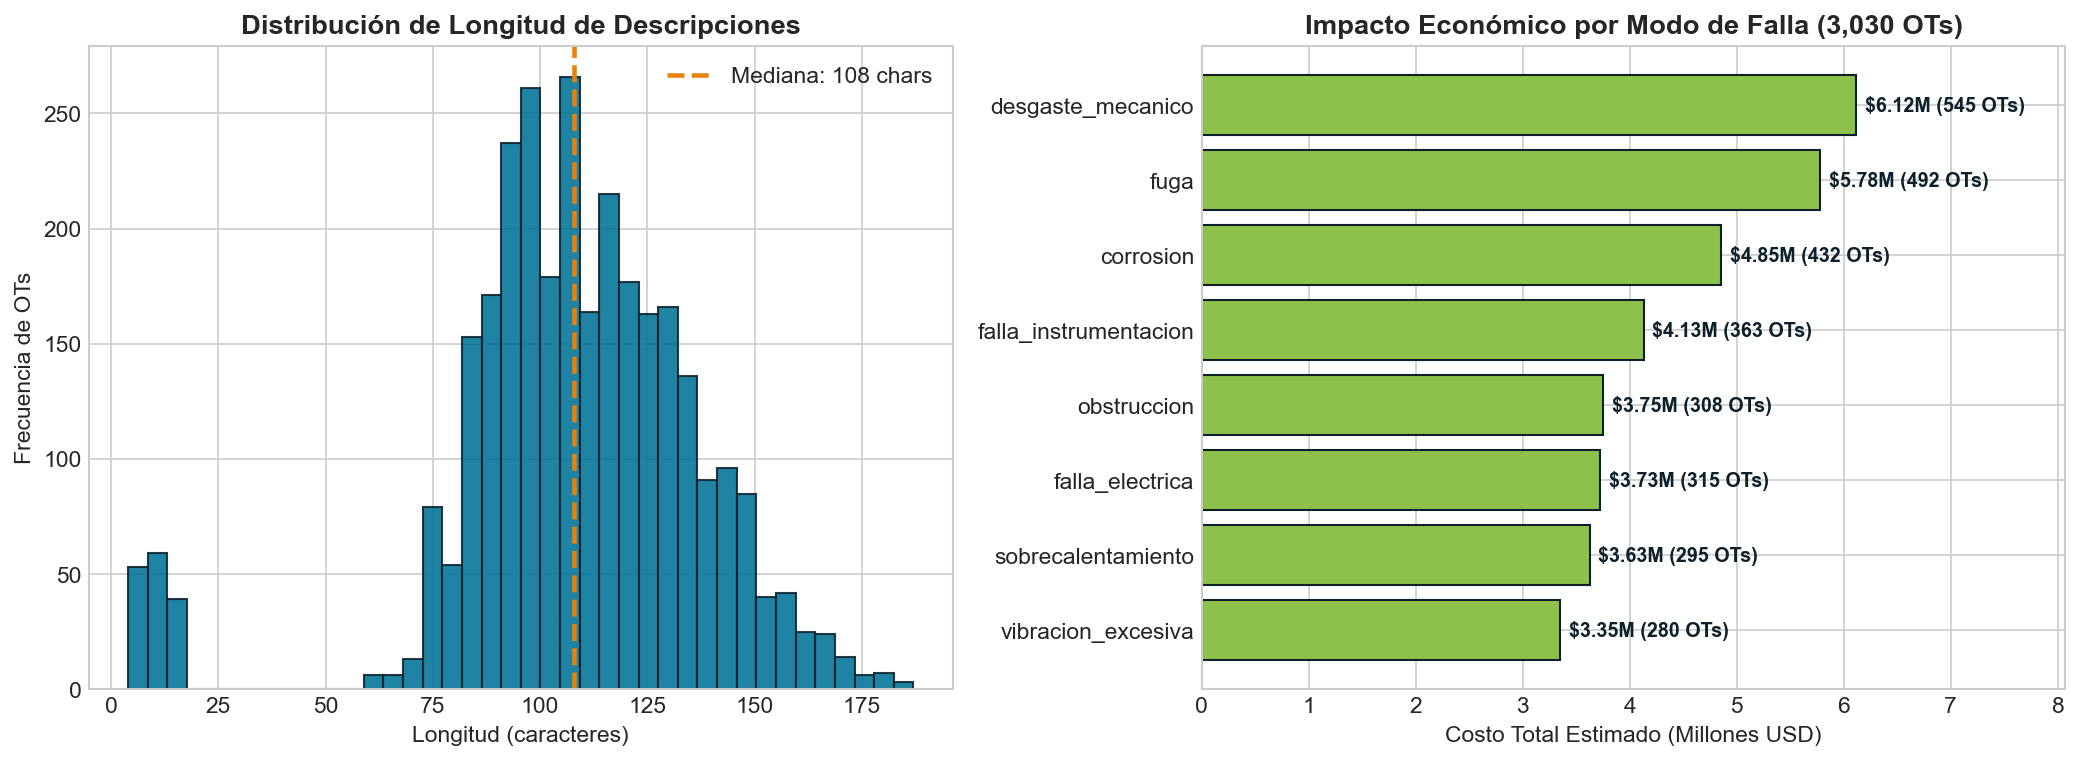

In [9]:
df["largo_descripcion"] = df["descripcion_problema"].fillna("").apply(len)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))
axes[0].hist(df["largo_descripcion"], bins=40, color=PUNGO_BLUE, edgecolor=PUNGO_NAVY, alpha=0.88)
med = df["largo_descripcion"].median()
axes[0].axvline(med, color=PUNGO_AMBER, linestyle="--", linewidth=2.2, label=f"Mediana: {med:.0f} chars")
axes[0].set_xlabel("Longitud (caracteres)")
axes[0].set_ylabel("Frecuencia de OTs")
axes[0].set_title("Distribución de Longitud de Descripciones")
axes[0].legend()

pareto = (
    df.groupby("modo_falla")
    .agg(conteo=("wo_id", "count"), costo_musd=("costo_estimado_usd", lambda s: s.sum() / 1e6))
    .sort_values("costo_musd", ascending=True)
)
bars = axes[1].barh(pareto.index, pareto["costo_musd"], color=PUNGO_LIME, edgecolor=PUNGO_NAVY)
for bar, (_, r) in zip(bars, pareto.iterrows()):
    axes[1].text(
        bar.get_width() + 0.08,
        bar.get_y() + bar.get_height() / 2,
        f"${r['costo_musd']:.2f}M ({int(r['conteo'])} OTs)",
        va="center",
        fontsize=9.5,
        fontweight="bold",
        color=PUNGO_NAVY,
    )
axes[1].set_xlim(0, pareto["costo_musd"].max() * 1.32)
axes[1].set_xlabel("Costo Total Estimado (Millones USD)")
axes[1].set_title("Impacto Económico por Modo de Falla (3,030 OTs)")

plt.tight_layout()
plt.show()

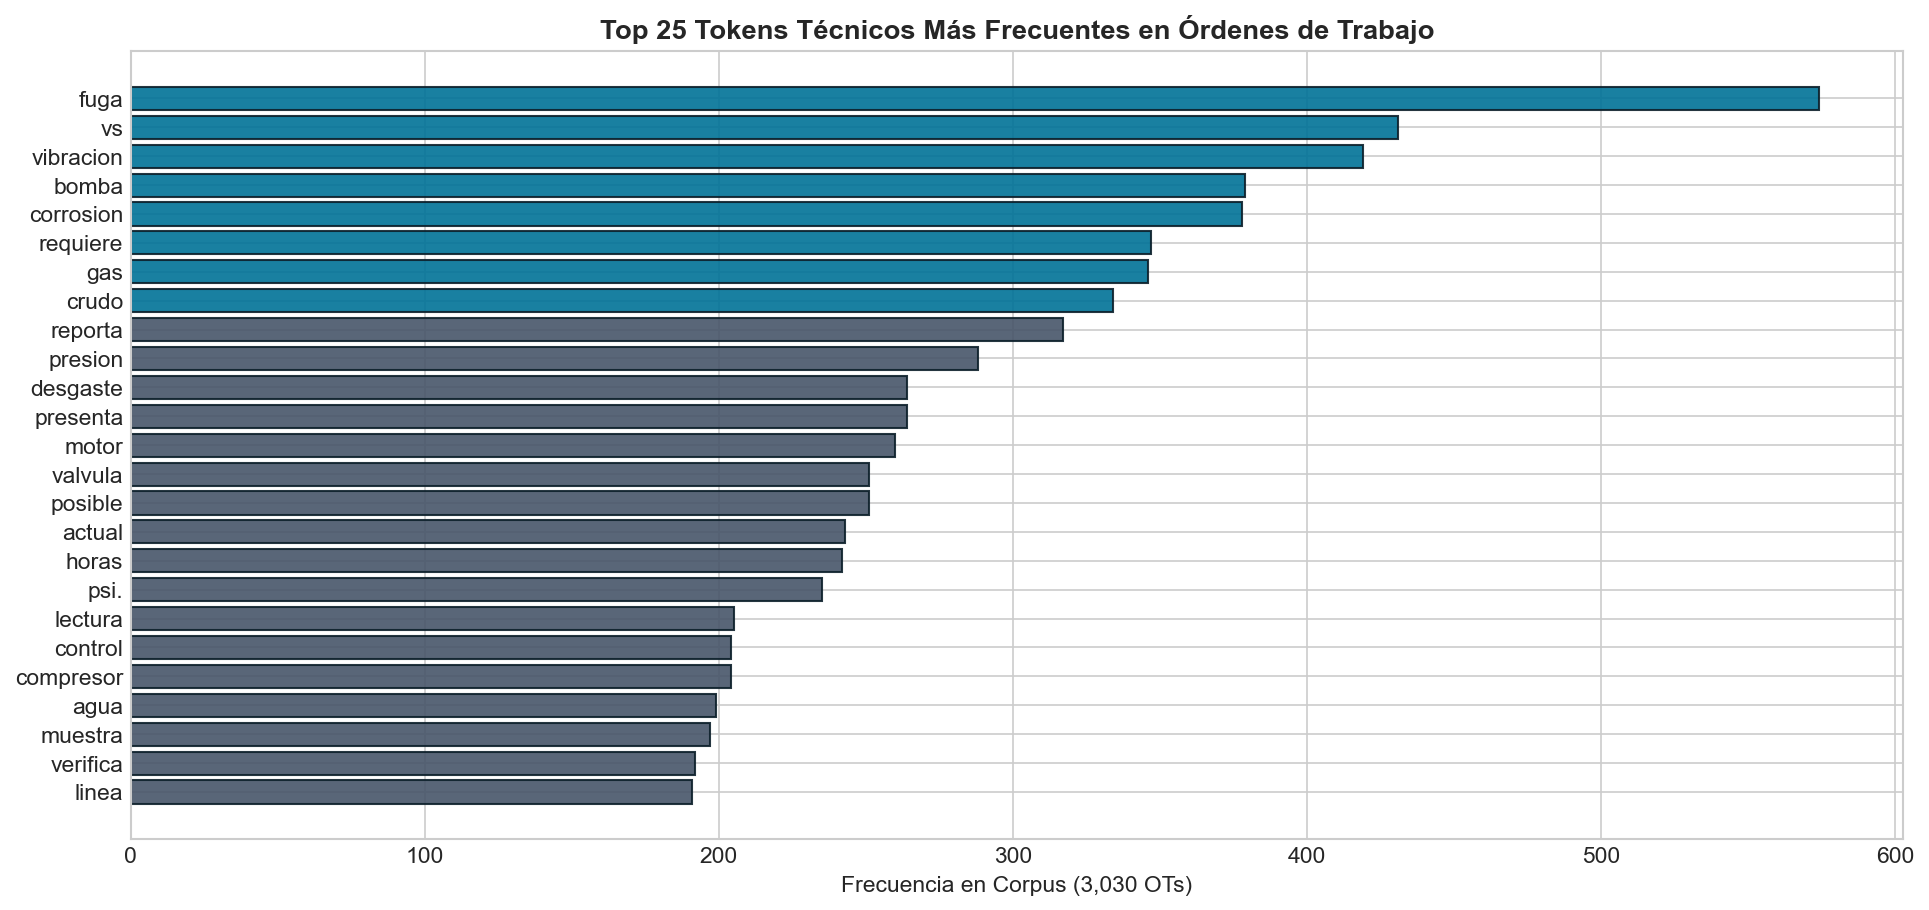

In [10]:
all_tokens = [token for tokens in df["tokens"] for token in tokens]
word_freq = Counter(all_tokens)
top_25 = word_freq.most_common(25)
palabras, frecuencias = zip(*top_25)

plt.figure(figsize=(13, 6.2))
colors = [PUNGO_BLUE if i < 8 else PUNGO_SLATE for i in range(len(palabras))]
plt.barh(range(len(palabras) - 1, -1, -1), frecuencias, color=colors, edgecolor=PUNGO_NAVY, alpha=0.9)
plt.yticks(range(len(palabras) - 1, -1, -1), palabras)
plt.xlabel("Frecuencia en Corpus (3,030 OTs)")
plt.title("Top 25 Tokens Técnicos Más Frecuentes en Órdenes de Trabajo")
plt.tight_layout()
plt.show()

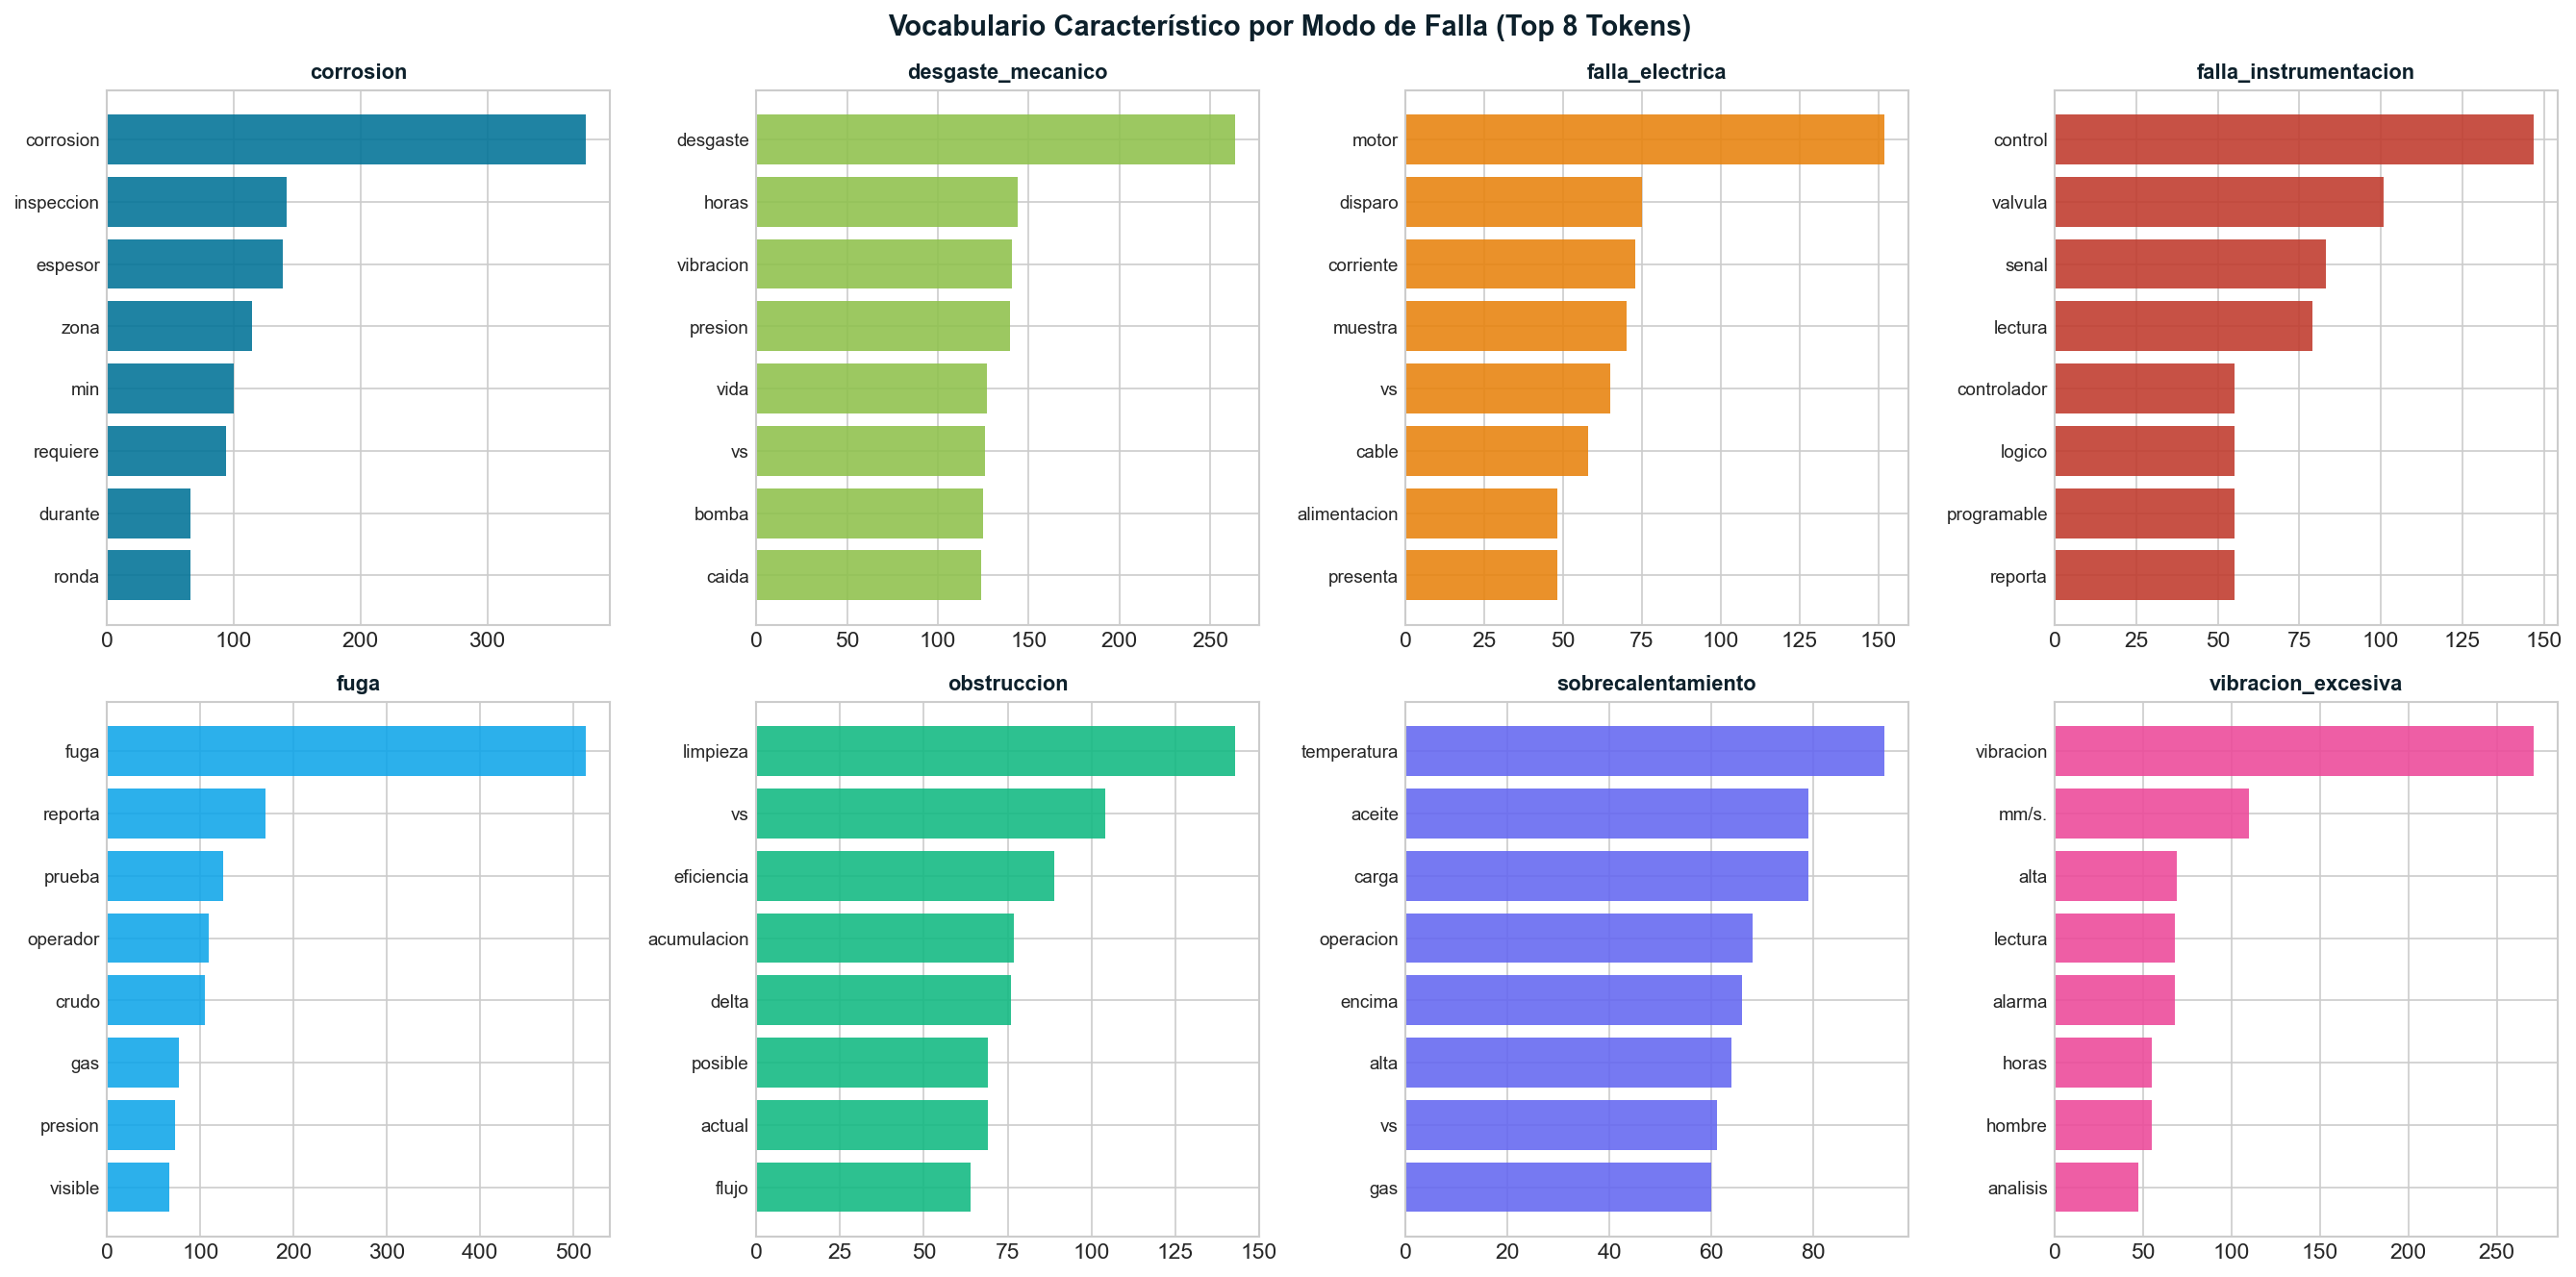

In [11]:
fig, axes = plt.subplots(2, 4, figsize=(18, 9))
axes = axes.flatten()
palette = [PUNGO_BLUE, PUNGO_LIME, PUNGO_AMBER, PUNGO_RED, "#0EA5E9", "#10B981", "#6366F1", "#EC4899"]

for idx, modo in enumerate(sorted(df["modo_falla"].unique())):
    tokens_modo = [t for tokens in df[df["modo_falla"] == modo]["tokens"] for t in tokens]
    top_8 = Counter(tokens_modo).most_common(8)
    palabras_m, freq_m = zip(*top_8)
    axes[idx].barh(range(len(palabras_m) - 1, -1, -1), freq_m, color=palette[idx % len(palette)], alpha=0.88)
    axes[idx].set_yticks(range(len(palabras_m) - 1, -1, -1))
    axes[idx].set_yticklabels(palabras_m, fontsize=9)
    axes[idx].set_title(modo, fontsize=10.5, fontweight="bold", color=PUNGO_NAVY)

plt.suptitle("Vocabulario Característico por Modo de Falla (Top 8 Tokens)", fontsize=14, fontweight="bold", color=PUNGO_NAVY)
plt.tight_layout()
plt.show()

## 6. Vectorización TF-IDF con Unigramas y Bigramas
Convertimos el texto limpio en una matriz dispersa de pesos `TF-IDF = TF × log(N / df)` limitando a las 500 características más informativas.

In [12]:
tfidf = TfidfVectorizer(
    max_features=500,
    min_df=5,
    max_df=0.95,
    ngram_range=(1, 2),
)
tfidf_matrix = tfidf.fit_transform(df["descripcion_limpia"])
densidad = tfidf_matrix.nnz / (tfidf_matrix.shape[0] * tfidf_matrix.shape[1])

print(f"Matriz TF-IDF shape : {tfidf_matrix.shape}")
print(f"  → Documentos      : {tfidf_matrix.shape[0]:,}")
print(f"  → Features (1-2g) : {tfidf_matrix.shape[1]}")
print(f"  → Densidad        : {densidad:.4f} ({densidad:.2%} celdas no nulas)")

Matriz TF-IDF shape : (3030, 500)
  → Documentos      : 3,030
  → Features (1-2g) : 500
  → Densidad        : 0.0366 (3.66% celdas no nulas)


In [13]:
feature_names = tfidf.get_feature_names_out()
print("TÉRMINOS MÁS DISCRIMINANTES POR MODO DE FALLA (TF-IDF PROMEDIO)")
print("=" * 64)
for modo in sorted(df["modo_falla"].unique()):
    mask = (df["modo_falla"] == modo).values
    mean_tfidf = tfidf_matrix[mask].mean(axis=0).A1
    top_indices = mean_tfidf.argsort()[-6:][::-1]
    top_str = ", ".join(f"{feature_names[i]} ({mean_tfidf[i]:.3f})" for i in top_indices)
    print(f"  {modo:22s} → {top_str}")

TÉRMINOS MÁS DISCRIMINANTES POR MODO DE FALLA (TF-IDF PROMEDIO)
  corrosion              → corrosion (0.149), de (0.124), en (0.096), espesor (0.080), inspeccion (0.080), reparacion (0.063)
  desgaste_mecanico      → de (0.092), desgaste (0.075), de rodamiento (0.053), rodamiento (0.050), del (0.048), desgaste de (0.047)
  falla_electrica        → de (0.154), motor (0.109), corriente (0.090), se (0.089), disparo (0.084), aislamiento (0.084)
  falla_instrumentacion  → de (0.129), de control (0.107), control (0.107), verificacion (0.084), sin (0.082), senal (0.076)
  fuga                   → fuga (0.148), de (0.092), en (0.088), por (0.069), reporta (0.062), reporta fuga (0.058)
  obstruccion            → de (0.128), limpieza (0.116), fouling (0.103), eficiencia (0.085), acumulacion de (0.081), acumulacion (0.081)
  sobrecalentamiento     → temperatura (0.125), de (0.116), del (0.100), carga (0.089), de operacion (0.073), operacion (0.067)
  vibracion_excesiva     → vibracion (0.212), mm

## 7. Resumen del Módulo 1
1. El texto de planta contiene abreviaturas, typos y **tags alfanuméricos** (`P-101A`, `93°C`) que deben preservarse durante la limpieza.
2. El corpus de 3,030 órdenes acumula **$38.9M USD** estimados, con `desgaste_mecanico`, `fuga` y `corrosion` liderando el volumen operativo.
3. **TF-IDF (1,2-gramas)** revela firmas léxicas claramente separables por modo de falla, habilitando modelos supervisados y comparativas con LLMs en el Módulo 2.